In [65]:
import os

from sentence_transformers import SentenceTransformer, util
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

In [54]:
# Load a pre-trained model
# model = SentenceTransformer('paraphrase-MiniLM-L6-v2')
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Input image names
image_names = [
    ('Cam3_H243_discount_14.png', 'Cam3_H243_discount_15.png'),
    ('Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png', 'Cam2_H255_discaunt_29012024_2024-02-06-11h11m10s095.png'),
    ('Cam3_H245_discount_9.png', 'Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png')
]

# Function to preprocess names
def preprocess(name):
    # Remove file extension
    name = os.path.splitext(name)[0]
    # Split by underscores
    words = name.replace('_', " ")
    return words

# Preprocess the names
preprocessed_names = [(preprocess(name1), preprocess(name2)) for name1, name2 in image_names]

# Generate embeddings and compute cosine similarity
def compute_similarity(pair, model):
    words1, words2 = pair
    # Generate embeddings for each word
    embeddings1 = model.encode(words1)
    embeddings2 = model.encode(words2)

    # Compute cosine similarity
    similarity = cosine_similarity([embeddings1], [embeddings2])[0][0]
    return similarity

# Calculate similarities for all pairs
similarities = [compute_similarity(pair, model) for pair in preprocessed_names]

# Print the results
for (name1, name2), similarity in zip(image_names, similarities):
    print(f"Similarity between '{name1}' and '{name2}': {similarity:.4f}")

Similarity between 'Cam3_H243_discount_14.png' and 'Cam3_H243_discount_15.png': 0.9771
Similarity between 'Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png' and 'Cam2_H255_discaunt_29012024_2024-02-06-11h11m10s095.png': 0.9952
Similarity between 'Cam3_H245_discount_9.png' and 'Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png': 0.5913


In [55]:
base_path = "/mnt/pg-fs01/Current/DB/ObjectDetectionV3"
df = pd.read_csv(os.path.join(base_path, "images.csv"))
df.shape

(1032, 6)

In [56]:
df.head()

,id,name,width,height,batch,folder
0,bdd640fb-0667-4ad1-9c80-317fa3b1799d,Cam3_H243_discount_14.png,640.0,480.0,batch1_10.5,batch1
1,fc377a4c-4a15-444d-85e7-ce8a3a578a8e,Cam3_H243_discount_15.png,640.0,480.0,batch1_10.5,batch1
2,ff50bde4-3825-47b8-9cab-cc97663f1c97,Cam3_H243_discount_16.png,640.0,480.0,batch1_10.5,batch1
3,5cec4eb5-edd9-4831-9ca3-5cfb04fc6d82,Cam3_H243_discount_17.png,640.0,480.0,batch1_10.5,batch1
4,b92da22b-21df-406f-8a0b-3c3336d8393a,Cam3_H243_discount_18.png,640.0,480.0,batch1_10.5,batch1


In [57]:
names = df["name"].values
names = np.unique(names)
names.shape

(970,)

In [58]:
preprocessed_names = [preprocess(name) for name in tqdm(names)]

embeddings = [model.encode(sentence, convert_to_tensor=True) for sentence in tqdm(preprocessed_names)]

100%|██████████| 970/970 [00:07<00:00, 133.99it/s]


In [63]:
distances = np.zeros((len(names), len(names)))
for i in tqdm(range(len(names))):
    for j in range(i, len(names)):
        similarity = util.pytorch_cos_sim(embeddings[i], embeddings[j]).cpu().numpy()[0][0]
        distances[i, j] = similarity
        distances[j, i] = similarity

100%|██████████| 970/970 [01:47<00:00,  9.02it/s]


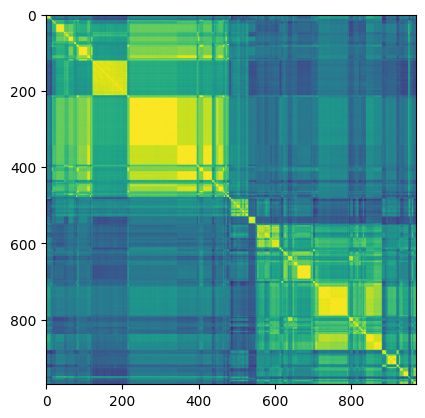

In [66]:
plt.imshow(distances)

In [67]:
np.save("distances_semantic_similrity.npy", distances)
np.save("names_semantic_similrity.npy", names)